# CitizenTech — Visão Computacional para Manutenção Urbana
**Global Solution 2026.2** · Detecção de fissuras em concreto (classificação binária)

**Integrantes (nome completo e RM):**
- Davi Barboza - 562370
- Rickelmy Omine - 563286
- Luca Schmidt - 560255

**Abordagem:** transferência de aprendizado (MobileNetV3-Small vs ResNet18) no dataset *Concrete Crack Images for Classification* (Mendeley), com divisão em blocos para reduzir vazamento entre treino/validação/teste, escolha de limiar orientada a *recall* e análise em imagens grandes por grade de blocos (tiles).

> Rode no **Google Colab** com GPU (Ambiente de execução → Alterar tipo → T4 GPU).

**Video Youtube**
https://youtu.be/neGvUiqcv4U

## 0. Setup

In [1]:
!pip -q install gradio opencv-python-headless scikit-learn matplotlib

In [2]:
import os, glob, random, time, platform, json
import numpy as np, matplotlib.pyplot as plt, cv2
import torch, torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, precision_recall_fscore_support, f1_score)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else platform.processor())

# ---- Configuração (ajuste aqui) ----
DATA_DIR = "/content/concrete_crack"   # pasta onde o dataset foi descompactado
IMG_SIZE = 224
BLOCK = 50                              # tamanho do bloco contíguo p/ split (ver seção 2)
N_TRAIN, N_VAL, N_TEST = 2000, 400, 400 # imagens POR CLASSE em cada conjunto
TARGET_RECALL = 0.95                    # triagem: preferimos não deixar fissura passar
BATCH, EPOCHS, LR = 64, 4, 3e-4
CLASSES = ["Sem fissura", "Com fissura"]

Dispositivo: cuda | Tesla T4


## 1. Dados
**Download manual** (o Mendeley exige o navegador): baixe o zip em <https://data.mendeley.com/datasets/5y9wdsg2zt/1>, envie para o Colab (ou Google Drive) e descompacte:

```python
!mkdir -p /content/concrete_crack
!unrar x -inul "/content/Concrete Crack Images for Classification.rar" /content/concrete_crack
```
O dataset tem pastas `Positive/` (com fissura) e `Negative/` (sem fissura), ~20 mil imagens 227×227 de cada.

In [3]:
!mkdir -p /content/concrete_crack
!unrar x -inul "/content/Concrete Crack Images for Classification.rar" /content/concrete_crack

Com fissura: 20000 | Sem fissura: 20000
Exemplo de nomes: ['00001.jpg', '00002.jpg', '00003.jpg']
Tamanho de uma imagem: (227, 227)


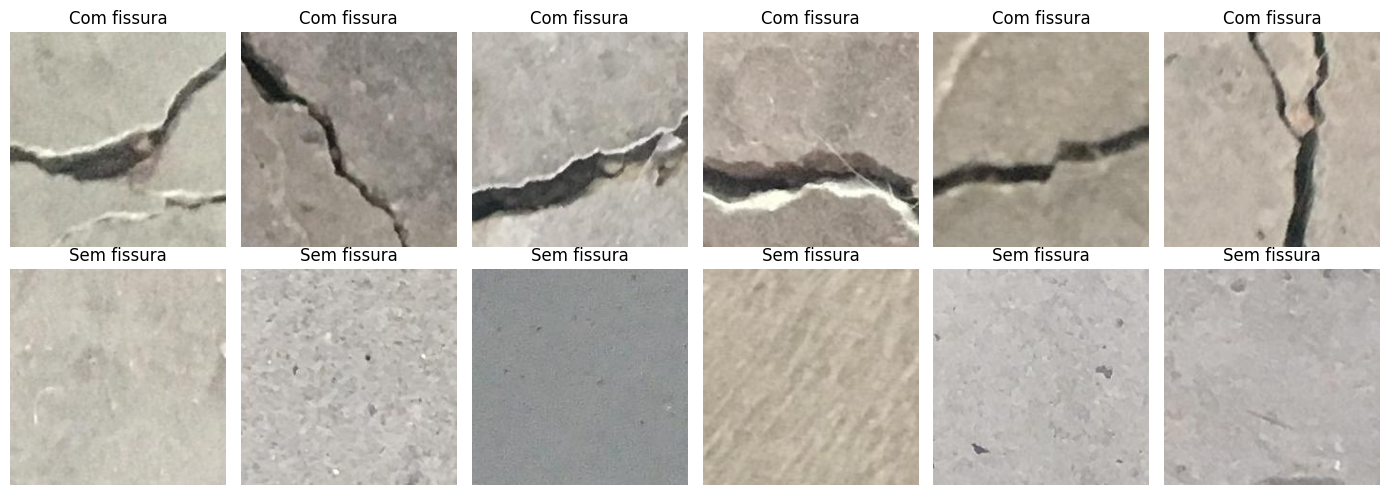

In [4]:
pos_files = sorted(glob.glob(f"{DATA_DIR}/**/Positive/*.*", recursive=True))
neg_files = sorted(glob.glob(f"{DATA_DIR}/**/Negative/*.*", recursive=True))
assert len(pos_files) > 0 and len(neg_files) > 0, "Não achei as pastas Positive/Negative em DATA_DIR."
print(f"Com fissura: {len(pos_files)} | Sem fissura: {len(neg_files)}")
print("Exemplo de nomes:", [os.path.basename(f) for f in pos_files[:3]])
print("Tamanho de uma imagem:", Image.open(pos_files[0]).size)

fig, ax = plt.subplots(2, 6, figsize=(14, 5))
for i in range(6):
    ax[0, i].imshow(Image.open(random.choice(pos_files))); ax[0, i].axis("off"); ax[0, i].set_title("Com fissura")
    ax[1, i].imshow(Image.open(random.choice(neg_files))); ax[1, i].axis("off"); ax[1, i].set_title("Sem fissura")
plt.tight_layout(); plt.show()

## 2. Divisão treino / validação / teste (sem misturar recortes da mesma origem)
O dataset foi gerado recortando poucas fotos grandes em milhares de patches. Dividir **aleatoriamente** imagem a imagem colocaria patches vizinhos (quase iguais) em conjuntos diferentes e **inflaria as métricas**.

Como os nomes dos arquivos não trazem o ID da foto original, usamos uma **heurística**: ordenamos os arquivos e dividimos em **blocos contíguos** (`BLOCK`); cada bloco inteiro vai para um único conjunto. Isso não garante 100% de separação, e essa limitação deve ser dita no relatório. A seção 7 traz um teste externo opcional para medir o quanto o modelo generaliza.

In [5]:
def block_split(files, block=BLOCK, frac=(0.70, 0.15, 0.15), seed=SEED):
    files = sorted(files)
    blocks = [files[i:i + block] for i in range(0, len(files), block)]
    random.Random(seed).shuffle(blocks)
    n = len(blocks); a = int(n * frac[0]); b = int(n * (frac[0] + frac[1]))
    flat = lambda bl: [f for blk in bl for f in blk]
    return flat(blocks[:a]), flat(blocks[a:b]), flat(blocks[b:])

def cap(files, n, seed=SEED):
    files = list(files); random.Random(seed).shuffle(files); return files[:n]

splits = {"train": [], "val": [], "test": []}
for label, files in [(1, pos_files), (0, neg_files)]:
    tr, va, te = block_split(files)
    splits["train"] += [(f, label) for f in cap(tr, N_TRAIN)]
    splits["val"]   += [(f, label) for f in cap(va, N_VAL)]
    splits["test"]  += [(f, label) for f in cap(te, N_TEST)]
for k, v in splits.items():
    print(k, len(v), "| positivos:", sum(l for _, l in v))

# garantia: nenhum arquivo em dois conjuntos
sets = {k: {f for f, _ in v} for k, v in splits.items()}
assert not (sets["train"] & sets["val"]) and not (sets["train"] & sets["test"]) and not (sets["val"] & sets["test"])

train 4000 | positivos: 2000
val 800 | positivos: 400
test 800 | positivos: 400


## 3. Pré-processamento e DataLoaders
Redimensionamento para 224×224 e normalização com média/desvio do ImageNet (exigido pelos pesos pré-treinados). No treino, aumento leve (flips e variação de brilho/contraste) para simular iluminação diferente.

In [6]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
tf_train = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
tf_eval = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class CrackDS(Dataset):
    def __init__(self, items, tf): self.items, self.tf = items, tf
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        p, y = self.items[i]
        return self.tf(Image.open(p).convert("RGB")), y

dl_train = DataLoader(CrackDS(splits["train"], tf_train), batch_size=BATCH, shuffle=True, num_workers=2)
dl_val   = DataLoader(CrackDS(splits["val"], tf_eval), batch_size=BATCH, num_workers=2)
dl_test  = DataLoader(CrackDS(splits["test"], tf_eval), batch_size=BATCH, num_workers=2)

## 4. Modelos (transferência de aprendizado)
Comparamos duas arquiteturas pré-treinadas no ImageNet, trocando apenas a camada final para 2 classes:
- **MobileNetV3-Small**: leve e rápida, boa para processar vídeo/monitoramento em equipamentos modestos.
- **ResNet18**: maior, tende a ser um pouco mais precisa.

In [7]:
def build_model(name):
    if name == "mobilenet_v3_small":
        m = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, 2)
    elif name == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, 2)
    else:
        raise ValueError(name)
    return m

@torch.no_grad()
def get_probs(model, loader):
    model.eval(); P, Y = [], []
    for x, y in loader:
        P.append(torch.softmax(model(x.to(device)), 1)[:, 1].cpu()); Y.append(y)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

def train_model(name, epochs=EPOCHS, lr=LR):
    model = build_model(name).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    crit = nn.CrossEntropyLoss()
    best_f1, best_state = -1, None
    for ep in range(epochs):
        model.train(); t0 = time.time(); tot = 0
        for x, y in dl_train:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); loss = crit(model(x), y); loss.backward(); opt.step()
            tot += loss.item() * len(y)
        pv, yv = get_probs(model, dl_val)
        f1 = f1_score(yv, pv >= 0.5)
        print(f"[{name}] época {ep+1}/{epochs} | loss {tot/len(dl_train.dataset):.4f} | F1 val {f1:.4f} | {time.time()-t0:.0f}s")
        if f1 > best_f1:
            best_f1 = f1; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model

trained = {}
for name in ["mobilenet_v3_small", "resnet18"]:
    trained[name] = train_model(name)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 54.1MB/s]


[mobilenet_v3_small] época 1/4 | loss 0.0689 | F1 val 0.9988 | 25s
[mobilenet_v3_small] época 2/4 | loss 0.0097 | F1 val 0.9987 | 18s
[mobilenet_v3_small] época 3/4 | loss 0.0042 | F1 val 1.0000 | 21s
[mobilenet_v3_small] época 4/4 | loss 0.0045 | F1 val 1.0000 | 18s
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 172MB/s]


[resnet18] época 1/4 | loss 0.0413 | F1 val 0.9975 | 21s
[resnet18] época 2/4 | loss 0.0151 | F1 val 0.9987 | 19s
[resnet18] época 3/4 | loss 0.0078 | F1 val 0.9987 | 20s
[resnet18] época 4/4 | loss 0.0044 | F1 val 0.9987 | 19s


## 5. Avaliação
### 5.1 Comparação das arquiteturas (validação e teste, limiar 0,5)

In [8]:
rows = []
for name, model in trained.items():
    for split, dl in [("val", dl_val), ("test", dl_test)]:
        p, y = get_probs(model, dl)
        pr, rc, f1, _ = precision_recall_fscore_support(y, p >= 0.5, average="binary", zero_division=0)
        rows.append((name, split, pr, rc, f1))
print(f"{'modelo':22s} {'conj':5s} {'prec':>7s} {'recall':>7s} {'F1':>7s}")
for r in rows: print(f"{r[0]:22s} {r[1]:5s} {r[2]:7.4f} {r[3]:7.4f} {r[4]:7.4f}")

modelo                 conj     prec  recall      F1
mobilenet_v3_small     val    1.0000  1.0000  1.0000
mobilenet_v3_small     test   0.9950  1.0000  0.9975
resnet18               val    1.0000  0.9975  0.9987
resnet18               test   0.9950  1.0000  0.9975


### 5.2 Escolha do modelo final e do limiar de confiança
Para **triagem de inspeção**, deixar passar uma fissura (falso negativo) é pior do que mandar inspecionar um local sem dano (falso positivo). Por isso o limiar é escolhido **na validação** como o maior valor que ainda garante `recall ≥ TARGET_RECALL`. O teste só é usado depois, para reportar o resultado.

Limiar escolhido na validação: 1.000 (recall alvo 0.95)


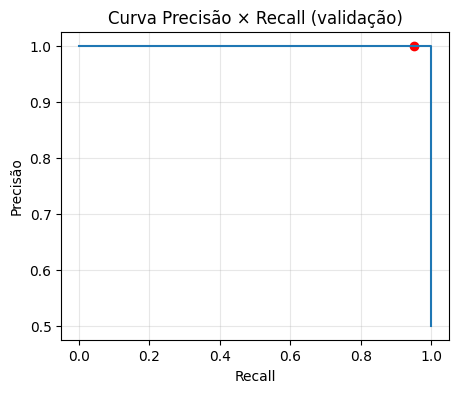

In [9]:
MODEL_NAME = "mobilenet_v3_small"   # <- troque para "resnet18" se for a melhor na tabela acima
model = trained[MODEL_NAME]

pv, yv = get_probs(model, dl_val)
prec, rec, th = precision_recall_curve(yv, pv)
ok = np.where(rec[:-1] >= TARGET_RECALL)[0]
THR = float(th[ok[-1]]) if len(ok) else 0.5
print(f"Limiar escolhido na validação: {THR:.3f} (recall alvo {TARGET_RECALL})")

plt.figure(figsize=(5, 4)); plt.plot(rec, prec); plt.scatter([rec[ok[-1]]], [prec[ok[-1]]], c="r") if len(ok) else None
plt.xlabel("Recall"); plt.ylabel("Precisão"); plt.title("Curva Precisão × Recall (validação)"); plt.grid(alpha=.3); plt.show()

### 5.3 Métricas no conjunto de teste


===== Teste | limiar 0.500 =====
              precision    recall  f1-score   support

 Sem fissura     1.0000    0.9950    0.9975       400
 Com fissura     0.9950    1.0000    0.9975       400

    accuracy                         0.9975       800
   macro avg     0.9975    0.9975    0.9975       800
weighted avg     0.9975    0.9975    0.9975       800



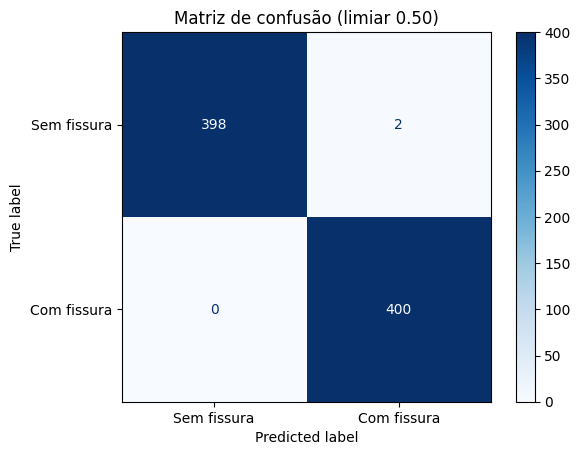


===== Teste | limiar 1.000 =====
              precision    recall  f1-score   support

 Sem fissura     0.9685    1.0000    0.9840       400
 Com fissura     1.0000    0.9675    0.9835       400

    accuracy                         0.9838       800
   macro avg     0.9843    0.9838    0.9837       800
weighted avg     0.9843    0.9838    0.9837       800



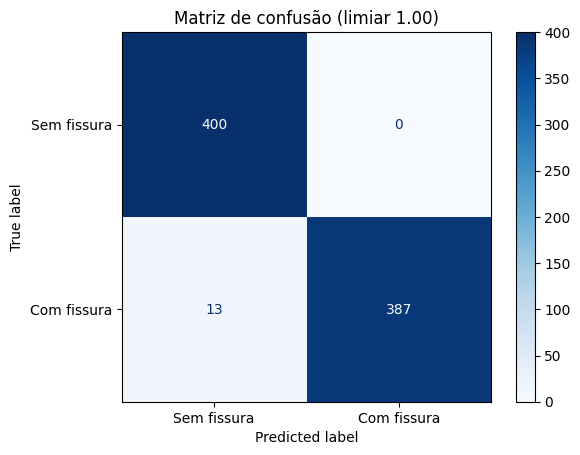

In [10]:
pt, yt = get_probs(model, dl_test)
for thr in [0.5, THR]:
    pred = (pt >= thr).astype(int)
    print(f"\n===== Teste | limiar {thr:.3f} =====")
    print(classification_report(yt, pred, target_names=CLASSES, digits=4))
    ConfusionMatrixDisplay(confusion_matrix(yt, pred), display_labels=CLASSES).plot(cmap="Blues", values_format="d")
    plt.title(f"Matriz de confusão (limiar {thr:.2f})"); plt.show()

### 5.4 Análise de erros
Observe nos exemplos abaixo se os erros têm relação com **sombras, textura rugosa, manchas, juntas, iluminação ou obstáculos**, e use isso na análise do relatório.

Falsos positivos: 0 | Falsos negativos: 13
Nenhum exemplo.


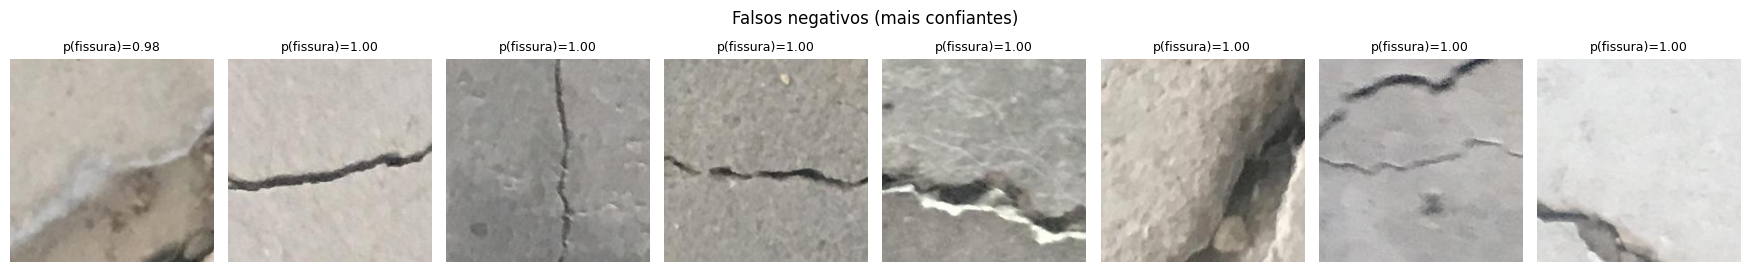

In [11]:
pred = (pt >= THR).astype(int)
test_items = splits["test"]
fp = [i for i in range(len(yt)) if yt[i] == 0 and pred[i] == 1]
fn = [i for i in range(len(yt)) if yt[i] == 1 and pred[i] == 0]
print(f"Falsos positivos: {len(fp)} | Falsos negativos: {len(fn)}")

def show(idx, title):
    idx = idx[:8]
    if not idx: print("Nenhum exemplo."); return
    fig, ax = plt.subplots(1, len(idx), figsize=(2.2 * len(idx), 2.8), squeeze=False)
    for a, i in zip(ax[0], idx):
        a.imshow(Image.open(test_items[i][0])); a.axis("off"); a.set_title(f"p(fissura)={pt[i]:.2f}", fontsize=9)
    fig.suptitle(title); plt.tight_layout(); plt.show()
show(sorted(fp, key=lambda i: -pt[i]), "Falsos positivos (mais confiantes)")
show(sorted(fn, key=lambda i: pt[i]), "Falsos negativos (mais confiantes)")

## 6. Desempenho: latência e FPS
Informe **equipamento e resolução** no relatório. Medimos (a) só o modelo e (b) o fluxo completo (pré-processamento + modelo) em imagens reais, em GPU e CPU, com lote = 1.

In [12]:
def sync(dev):
    if dev == "cuda": torch.cuda.synchronize()

@torch.no_grad()
def bench(model, dev, n=200):
    m = model.to(dev).eval()
    x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=dev)
    for _ in range(20): m(x)
    sync(dev); t = time.perf_counter()
    for _ in range(n): m(x)
    sync(dev); only_model = (time.perf_counter() - t) / n * 1000
    paths = [p for p, _ in random.sample(splits["test"], 100)]
    sync(dev); t = time.perf_counter()
    for p in paths:
        xi = tf_eval(Image.open(p).convert("RGB")).unsqueeze(0).to(dev)
        m(xi)
    sync(dev); e2e = (time.perf_counter() - t) / len(paths) * 1000
    return only_model, e2e

print("CPU:", platform.processor() or platform.machine(), "| núcleos:", os.cpu_count(), "| entrada:", f"{IMG_SIZE}x{IMG_SIZE}")
results_perf = {}
for name, m in trained.items():
    for dev in (["cuda"] if device == "cuda" else []) + ["cpu"]:
        a, b = bench(m, dev)
        results_perf[(name, dev)] = (a, b)
        print(f"{name:20s} {dev:5s} | só modelo: {a:6.2f} ms ({1000/a:6.1f} FPS) | completo: {b:6.2f} ms ({1000/b:6.1f} FPS)")
trained[MODEL_NAME].to(device); model = trained[MODEL_NAME]

CPU: x86_64 | núcleos: 2 | entrada: 224x224
mobilenet_v3_small   cuda  | só modelo:   6.44 ms ( 155.3 FPS) | completo:   7.60 ms ( 131.6 FPS)
mobilenet_v3_small   cpu   | só modelo:   9.55 ms ( 104.7 FPS) | completo:  12.00 ms (  83.3 FPS)
resnet18             cuda  | só modelo:   2.54 ms ( 393.7 FPS) | completo:   4.77 ms ( 209.5 FPS)
resnet18             cpu   | só modelo:  59.67 ms (  16.8 FPS) | completo:  61.62 ms (  16.2 FPS)


## 7. (Opcional, recomendado) Teste externo: generalização para outro domínio
Se baixar o **SDNET2018** (<https://doi.org/10.15142/T3TD19>), aponte abaixo para uma pasta de imagens com fissura (`CD`) e uma sem (`UD`), por exemplo de pavimentos (`P`) ou paredes (`W`). É esperado que as métricas **caiam** em relação ao teste interno; esse contraste mostra o limite do modelo e rende uma boa análise crítica.

In [13]:
EXT_POS_DIR = None   # ex.: "/content/SDNET2018/P/CP"  (com fissura)
EXT_NEG_DIR = None   # ex.: "/content/SDNET2018/P/UP"  (sem fissura)
N_EXT = 300

if EXT_POS_DIR and EXT_NEG_DIR:
    ep = cap(glob.glob(f"{EXT_POS_DIR}/*.jpg") + glob.glob(f"{EXT_POS_DIR}/*.png"), N_EXT)
    en = cap(glob.glob(f"{EXT_NEG_DIR}/*.jpg") + glob.glob(f"{EXT_NEG_DIR}/*.png"), N_EXT)
    ext_items = [(f, 1) for f in ep] + [(f, 0) for f in en]
    dl_ext = DataLoader(CrackDS(ext_items, tf_eval), batch_size=BATCH, num_workers=2)
    pe, ye = get_probs(model, dl_ext)
    print(classification_report(ye, (pe >= THR).astype(int), target_names=CLASSES, digits=4))
else:
    print("Teste externo não configurado (opcional).")

Teste externo não configurado (opcional).


## 8. Integração ao CitizenTech
O modelo foi treinado em patches 227×227, mas fotos reais são maiores. Por isso a função de análise tem dois modos:
- **frame**: classifica a imagem inteira (rápido; bom para uma foto já recortada).
- **tiles**: divide a imagem em uma grade de blocos, classifica cada um e **marca em vermelho** os blocos suspeitos (resultado visual e localização aproximada).

Saída sempre com **confiança** e a mensagem de triagem. A presença de fissura na imagem **não** indica gravidade nem segurança estrutural; ela apenas sugere que o local seja inspecionado.

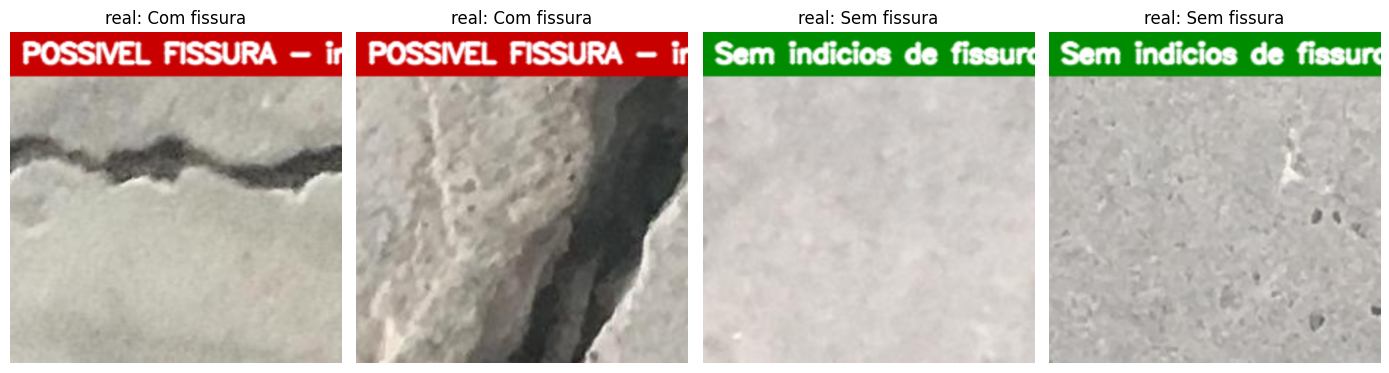

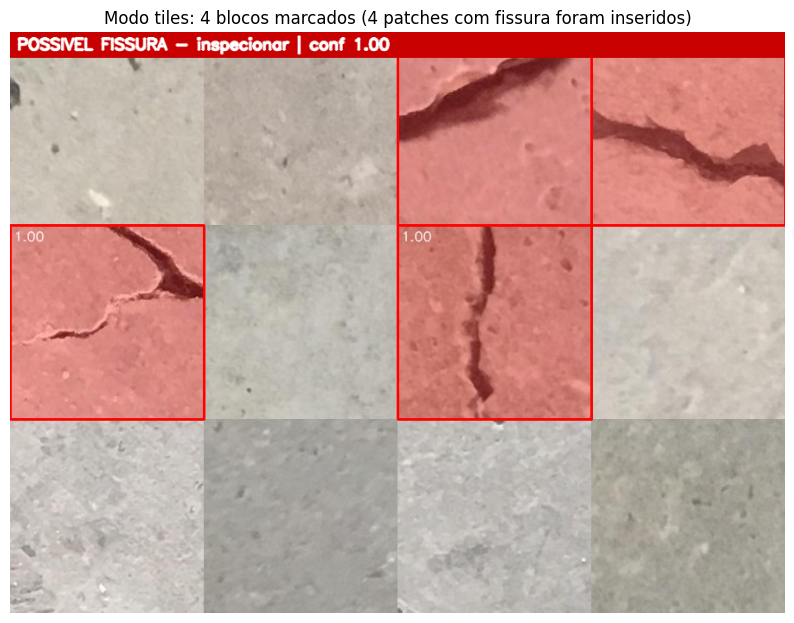

In [14]:
@torch.no_grad()
def classify_pils(model, pils, bs=64):
    model.eval(); out = []
    for i in range(0, len(pils), bs):
        x = torch.stack([tf_eval(p) for p in pils[i:i + bs]]).to(device)
        out.append(torch.softmax(model(x), 1)[:, 1].cpu())
    return torch.cat(out).numpy()

def analyze_bgr(model, img, mode="tiles", thr=None, tile=IMG_SIZE):
    thr = THR if thr is None else thr
    out = img.copy(); h, w = img.shape[:2]
    if mode == "frame":
        p = float(classify_pils(model, [Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))])[0])
        hit = p >= thr; conf = p; boxes = []
    else:
        rows, cols = max(1, round(h / tile)), max(1, round(w / tile))
        ch, cw = h // rows, w // cols
        pils, coords = [], []
        for r in range(rows):
            for c in range(cols):
                y0, x0 = r * ch, c * cw
                crop = img[y0:y0 + ch, x0:x0 + cw]
                pils.append(Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))); coords.append((x0, y0, cw, ch))
        probs = classify_pils(model, pils)
        boxes = [(co, float(p)) for co, p in zip(coords, probs) if p >= thr]
        hit = len(boxes) > 0; conf = float(probs.max())
        ov = out.copy()
        for (x0, y0, cw_, ch_), p in boxes:
            cv2.rectangle(ov, (x0, y0), (x0 + cw_, y0 + ch_), (0, 0, 255), -1)
        out = cv2.addWeighted(ov, 0.30, out, 0.70, 0)
        for (x0, y0, cw_, ch_), p in boxes:
            cv2.rectangle(out, (x0, y0), (x0 + cw_, y0 + ch_), (0, 0, 255), 2)
            cv2.putText(out, f"{p:.2f}", (x0 + 4, y0 + 18), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)
    txt = f"POSSIVEL FISSURA - inspecionar | conf {conf:.2f}" if hit else f"Sem indicios de fissura | p(fissura) max {conf:.2f}"
    color = (0, 0, 200) if hit else (0, 140, 0)
    cv2.rectangle(out, (0, 0), (w, 30), color, -1)
    cv2.putText(out, txt, (8, 21), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2, cv2.LINE_AA)
    return out, hit, conf, len(boxes)

# Demonstração em imagens do teste (modo frame) e em uma imagem grande montada (modo tiles)
demo = random.sample(splits["test"], 4)
fig, ax = plt.subplots(1, 4, figsize=(14, 4))
for a, (p, y) in zip(ax, demo):
    o, hit, conf, _ = analyze_bgr(model, cv2.imread(p), "frame")
    a.imshow(cv2.cvtColor(cv2.resize(o, (454, 454)), cv2.COLOR_BGR2RGB)); a.axis("off"); a.set_title(f"real: {CLASSES[y]}")
plt.tight_layout(); plt.show()

# imagem grande = mosaico 3x4 de patches de teste (simula uma foto maior)
mos_items = random.sample([i for i in splits["test"] if i[1] == 0], 8) + random.sample([i for i in splits["test"] if i[1] == 1], 4)
random.shuffle(mos_items)
imgs = [cv2.resize(cv2.imread(p), (IMG_SIZE, IMG_SIZE)) for p, _ in mos_items]
mosaic = np.vstack([np.hstack(imgs[r * 4:(r + 1) * 4]) for r in range(3)])
o, hit, conf, nb_ = analyze_bgr(model, mosaic, "tiles")
plt.figure(figsize=(10, 8)); plt.imshow(cv2.cvtColor(o, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title(f"Modo tiles: {nb_} blocos marcados (4 patches com fissura foram inseridos)"); plt.show()

### 8.1 Processamento de vídeo / sequência de imagens
Use um vídeo curto de rua/parede/pavimento (`VIDEO_IN`). Sem vídeo, o notebook gera uma sequência a partir de imagens do teste para simular o monitoramento. A função registra **latência média e FPS de processamento**.

In [15]:
def process_video(src, dst, model, mode="tiles", every=1, thr=None, max_frames=300):
    cap_ = cv2.VideoCapture(src)
    fps_in = cap_.get(cv2.CAP_PROP_FPS) or 25
    W, H = int(cap_.get(3)), int(cap_.get(4))
    wr = cv2.VideoWriter(dst, cv2.VideoWriter_fourcc(*"mp4v"), fps_in / every, (W, H))
    n = k = alerts = 0; t_proc = 0.0
    while True:
        ok, fr = cap_.read()
        if not ok or n >= max_frames: break
        k += 1
        if (k - 1) % every: continue
        sync(device); t = time.perf_counter()
        out, hit, conf, nbox = analyze_bgr(model, fr, mode, thr)
        sync(device); t_proc += time.perf_counter() - t
        alerts += int(hit); n += 1; wr.write(out)
    cap_.release(); wr.release()
    stats = dict(frames=n, resolucao=f"{W}x{H}", modo=mode, latencia_media_ms=1000 * t_proc / max(n, 1),
                 fps_processamento=n / max(t_proc, 1e-9), frames_com_alerta=alerts)
    print(json.dumps(stats, indent=2, ensure_ascii=False)); return stats

VIDEO_IN = None   # ex.: "/content/rua.mp4"
if VIDEO_IN is None:
    seq = [p for p, _ in random.sample(splits["test"], 40)]
    vw = cv2.VideoWriter("/content/sequencia_demo.mp4", cv2.VideoWriter_fourcc(*"mp4v"), 10, (640, 480))
    for p in seq:
        f = cv2.resize(cv2.imread(p), (640, 480))
        for _ in range(5): vw.write(f)
    vw.release(); VIDEO_IN = "/content/sequencia_demo.mp4"
    print("Sequência simulada criada a partir de imagens do teste.")

stats_frame = process_video(VIDEO_IN, "/content/saida_frame.mp4", model, mode="frame")
stats_tiles = process_video(VIDEO_IN, "/content/saida_tiles.mp4", model, mode="tiles")
# Para exibir no navegador do Colab, converta para H.264:
# !ffmpeg -y -loglevel error -i /content/saida_tiles.mp4 -vcodec libx264 /content/saida_tiles_h264.mp4

Sequência simulada criada a partir de imagens do teste.
{
  "frames": 200,
  "resolucao": "640x480",
  "modo": "frame",
  "latencia_media_ms": 10.755388575001916,
  "fps_processamento": 92.97665007884866,
  "frames_com_alerta": 100
}
{
  "frames": 200,
  "resolucao": "640x480",
  "modo": "tiles",
  "latencia_media_ms": 18.577263580002636,
  "fps_processamento": 53.82924108782323,
  "frames_com_alerta": 80
}


### 8.2 Interface (demo para o vídeo) e API para o protótipo
A interface Gradio abaixo mostra upload de imagem, modo, limiar e resultado com confiança. Para plugar no CitizenTech real, salve o modelo e exponha o endpoint FastAPI da célula seguinte.

In [16]:
import gradio as gr

def gr_fn(img_rgb, mode, thr):
    if img_rgb is None:
        return None, "Envie uma foto para analisar."
    bgr = cv2.cvtColor(np.array(img_rgb), cv2.COLOR_RGB2BGR)
    out, hit, conf, nbox = analyze_bgr(model, bgr, mode, thr)

    if hit:
        extra = f"; {nbox} bloco(s) marcado(s)" if mode == "tiles" else ""
        msg = f"POSSÍVEL FISSURA — encaminhar para inspeção (confiança {conf:.1%}{extra})"
    else:
        msg = f"Sem indícios de fissura (p máx = {conf:.1%})"
    msg += "\n\nAtenção: o resultado serve só para triagem e não mede gravidade nem segurança estrutural."
    return cv2.cvtColor(out, cv2.COLOR_BGR2RGB), msg

thr_default = float(min(max(THR, 0.05), 1.0))   # garante que o valor inicial cabe no slider

demo_ui = gr.Interface(
    gr_fn,
    inputs=[
        gr.Image(type="pil", label="Foto"),
        gr.Radio(["tiles", "frame"], value="tiles", label="Modo"),
        gr.Slider(0.05, 1.0, value=thr_default, step=0.001, label="Limiar de confiança"),
    ],
    outputs=[gr.Image(label="Resultado"), gr.Textbox(label="Triagem")],
    title="CitizenTech · Triagem de fissuras",
)
demo_ui.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://950764a6fee4b2e4bf.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [17]:
torch.save({"arch": MODEL_NAME, "state": {k: v.cpu() for k, v in model.state_dict().items()}, "thr": THR}, "crack_model.pt")
print("Modelo salvo em crack_model.pt (limiar:", round(THR, 3), ")")

Modelo salvo em crack_model.pt (limiar: 1.0 )


In [18]:
%%writefile api_citizentech.py
# Endpoint de exemplo para integrar ao backend do CitizenTech
# pip install fastapi uvicorn python-multipart torch torchvision pillow
# uvicorn api_citizentech:app --host 0.0.0.0 --port 8000
import io, torch, torch.nn as nn
from fastapi import FastAPI, UploadFile, File
from PIL import Image
from torchvision import models, transforms

ck = torch.load("crack_model.pt", map_location="cpu")
if ck["arch"] == "mobilenet_v3_small":
    m = models.mobilenet_v3_small(); m.classifier[3] = nn.Linear(m.classifier[3].in_features, 2)
else:
    m = models.resnet18(); m.fc = nn.Linear(m.fc.in_features, 2)
m.load_state_dict(ck["state"]); m.eval()
THR = ck["thr"]
tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(),
                         transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
app = FastAPI(title="CitizenTech - Fissuras")

@app.post("/analisar")
async def analisar(file: UploadFile = File(...)):
    img = Image.open(io.BytesIO(await file.read())).convert("RGB")
    with torch.no_grad():
        p = torch.softmax(m(tf(img).unsqueeze(0)), 1)[0, 1].item()
    return {"possivel_fissura": p >= THR, "confianca": round(p, 4), "limiar": round(THR, 3),
            "aviso": "Triagem apenas; nao indica gravidade nem seguranca estrutural."}

Writing api_citizentech.py
